# Reproducing Figure 2 and Supplementary Figure 4 of Nadel et al. from the NWB files

This notebook recomputes every data panel of Figure 2 (D to N) and Supplementary Figure 4 (A to I) of Nadel et al. (bioRxiv, doi:10.64898/2026.07.29.741478) from the converted NWB files alone, and draws each panel next to the values the preprint reports in its supplementary statistics tables (`nadel_2026_paper_values.csv`, open markers).

The measurements follow the preprint methods, with the details that reproduce the lab's per-cell values:

- For firing rate and rheobase, spikes are upward crossings of 0 mV at least 5 ms apart, anywhere in the sweep. Firing rate is the number of spikes in the 2 s sweep divided by the 0.5 s step duration.
- Latency, mean ISI, and adaptation index come from the Allen Institute's ipfx package, as in the lab's analysis, with no filtering and spikes detected over the whole sweep. A run's latency is negative when its first spike comes before the step; a cell's latency at a current is the mean over its runs, left out when that mean is negative.
- Sag ratio is |V<sub>min</sub> - V<sub>ss</sub>| / |V<sub>min</sub> - V<sub>baseline</sub>|, with V<sub>ss</sub> the mean of the last 10% of the step and V<sub>baseline</sub> the mean before the step.
- Resting membrane potential is the mean voltage of the 30 s spontaneous recording.
- Rheobase is the smallest 50 ms step (5 pA increments) with a spike anywhere in the sweep. A run that never fires counts as its largest step plus 5 pA, and the runs of a cell are averaged. Cells without the 5 pA protocol use the F-I steps, counting only spikes in the first 50 ms of the step.
- Input resistance is the -5 mV voltage clamp test pulse divided by the change in current between the 100 ms before the step and the last 20 ms of the step, averaged over test pulse sweeps. Capacitance is the charge of the capacitive transient (current above its steady state during the step) of the cell's averaged test pulse, divided by the step.
- Each measurement is averaged over the runs of a cell, then over cells (mean and SEM across cells). Runs recorded while the cell was held near -60 mV with DC current (`held_near_minus_60_mV` in the sequential recordings table) are averaged with the runs at rest, as in the lab's analysis.
- Cells whose `in_preprint_figures` column is False are left out.
- In the bar panels (2J to 2M), outliers within each group are removed with the ROUT method (Q = 0.1%), as the preprint describes. The curve panels keep every cell, which matches the lab's values.

Reading all 34 files takes about ten minutes. ipfx 2.1.2 pins `pynwb==3.1.2`, so install it without its dependencies (`pip install ipfx==2.1.2 --no-deps`); the parts used here need only numpy, scipy, and pandas.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from ipfx.feature_extractor import SpikeFeatureExtractor, SpikeTrainFeatureExtractor
from pynwb import NWBHDF5IO
from scipy import optimize, stats

import lerner_lab_to_nwb.nadel_2026 as nadel_2026

output_dir_path = Path("/Volumes/T7/CatalystNeuro/Lerner/conversion_nwb")
paper_values = pd.read_csv(Path(nadel_2026.__file__).parent / "nadel_2026_paper_values.csv")

## Measure every sweep

In [2]:
FI_PROTOCOL = "PA_Ch1_CC excitability 20 pA steps to 200 pA"
SAG_PROTOCOL = "PA_Ch1_CC Ih -50 pA steps to -150 pA"
RHEOBASE_PROTOCOL = "PA_Ch1_CC excitability 5 pA steps to 100 pA"
SPONTANEOUS_PROTOCOL = "PA_Ch1_CC spont firing for 30s"
TEST_PULSE_PROTOCOL = "PA_Ch1_WC_VC_test pulse"


def to_physical_units(series):
    return series.data[:] * series.conversion + series.offset


def detect_zero_crossings(voltage, rate):
    """Return the times (s from sweep start) of upward crossings of 0 mV at least 5 ms apart (voltage in mV)."""
    above = voltage > 0.0
    crossings = []
    for index in np.flatnonzero(above[1:] & ~above[:-1]) + 1:
        if crossings and index - crossings[-1] < 0.005 * rate:
            continue
        crossings.append(index)
    return np.array(crossings) / rate


def spike_train_features(voltage, current, rate, start, stop):
    """Latency (ms), mean ISI (ms) and adaptation index of a sweep from ipfx, with no filtering and spikes over the whole sweep."""
    time = np.arange(len(voltage)) / rate
    spikes = SpikeFeatureExtractor(filter=None).process(time, voltage, current)
    train = SpikeTrainFeatureExtractor(start=start / rate, end=stop / rate).process(time, voltage, current, spikes)
    latency = train.get("latency", np.nan)
    return dict(
        latency=latency * 1e3,
        mean_isi=train.get("mean_isi", np.nan) * 1e3,
        adaptation_index=train.get("adapt", np.nan),
    )


def step_window(command):
    """Return the first and last-plus-one sample index of the step in a stimulus template."""
    changes = np.flatnonzero(np.diff(command) != 0)
    return changes[0] + 1, changes[-1] + 1


step_rows, spontaneous_rows, test_pulse_rows, cell_rows = [], [], [], []
for nwbfile_path in sorted(output_dir_path.glob("sub-*.nwb")):
    with NWBHDF5IO(nwbfile_path, mode="r") as io:
        nwbfile = io.read()
        age_group = "P40" if nwbfile.subject.age is not None else "P70"
        electrodes = nwbfile.intracellular_recordings.category_tables["electrodes"].to_dataframe()
        electrodes["electrode"] = [electrode.name for electrode in electrodes["electrode"]]
        for _, electrode in electrodes.drop_duplicates("electrode").iterrows():
            cell_rows.append(
                dict(
                    cell=nwbfile.icephys_electrodes[electrode["electrode"]].cell_id,
                    subject=nwbfile.subject.subject_id,
                    age_group=age_group,
                    projection_target=electrode["projection_target"],
                    stress_group=electrode["stress_group"],
                    in_preprint_figures=electrode["in_preprint_figures"],
                )
            )
        runs = nwbfile.get_icephys_sequential_recordings().to_dataframe()
        for _, run in runs.iterrows():
            prefix = Path(run["source_file"]).stem + "_sweep_"
            for name in sorted(name for name in nwbfile.acquisition if name.startswith(prefix)):
                response = nwbfile.acquisition[name]
                series_type = type(response).__name__
                cell = response.electrode.cell_id
                rate = response.rate
                if run["stimulus_type"] in (FI_PROTOCOL, SAG_PROTOCOL, RHEOBASE_PROTOCOL) and series_type == "CurrentClampSeries":
                    voltage = to_physical_units(response) * 1e3
                    command = to_physical_units(nwbfile.stimulus_template[name.replace("_response", "_stimulus_template")])
                    if run["stimulus_type"] == RHEOBASE_PROTOCOL:
                        start, stop = int(0.05 * rate), int(0.10 * rate)
                    else:
                        start, stop = int(0.5 * rate), int(1.0 * rate)
                    step = voltage[start:stop]
                    features = spike_train_features(voltage, command * 1e12, rate, start, stop) if run["stimulus_type"] == FI_PROTOCOL else {}
                    step_rows.append(
                        dict(
                            cell=cell,
                            protocol=run["stimulus_type"],
                            run=run["source_file"],
                            current_pA=int(round(command[start] * 1e12)),
                            step_onset_s=start / rate,
                            step_duration_s=(stop - start) / rate,
                            crossings_s=detect_zero_crossings(voltage, rate),
                            baseline_mV=voltage[:start].mean(),
                            step_min_mV=step.min(),
                            step_end_mV=step[-len(step) // 10 :].mean(),
                            **features,
                        )
                    )
                elif run["stimulus_type"] == SPONTANEOUS_PROTOCOL and series_type == "CurrentClampSeries":
                    spontaneous_rows.append(dict(cell=cell, run=run["source_file"], mean_mV=to_physical_units(response).mean() * 1e3))
                elif run["stimulus_type"] == TEST_PULSE_PROTOCOL and series_type == "VoltageClampSeries":
                    current = to_physical_units(response) * 1e12  # pA
                    command = to_physical_units(nwbfile.stimulus_template[name.replace("_response", "_stimulus_template")]) * 1e3  # mV
                    up, down = step_window(command)
                    test_pulse_rows.append(
                        dict(
                            cell=cell,
                            rate=rate,
                            current_pA=current[up - int(0.1 * rate) : down],
                            onset=int(0.1 * rate),
                            delta_voltage_mV=command[up] - command[up - 1],
                        )
                    )

cells = pd.DataFrame(cell_rows).drop_duplicates("cell").set_index("cell")
cells = cells[cells["in_preprint_figures"]]
steps = pd.DataFrame(step_rows)
steps = steps[steps["cell"].isin(cells.index)]
spontaneous = pd.DataFrame(spontaneous_rows)
spontaneous = spontaneous[spontaneous["cell"].isin(cells.index)]
test_pulses = pd.DataFrame(test_pulse_rows)
test_pulses = test_pulses[test_pulses["cell"].isin(cells.index)]
cells.groupby(["age_group", "projection_target", "stress_group"]).size().unstack()

/Users/pauladkisson/Documents/CatalystNeuro/LernerConv2/lerner-lab-to-nwb/.venv/lib/python3.12/site-packages/hdmf/spec/catalog.py:101: UserWarning: ndx-events.extensions defines a different specification for TimestampVectorData than the existing definition from nwb.event.yaml. Defaulting to the existing specification from nwb.event.yaml, but compatibility issues may be present. Please update the extension version if possible.
  self.register_spec(spec, source_file)
/Users/pauladkisson/Documents/CatalystNeuro/LernerConv2/lerner-lab-to-nwb/.venv/lib/python3.12/site-packages/hdmf/spec/catalog.py:101: UserWarning: ndx-events.extensions defines a different specification for DurationVectorData than the existing definition from nwb.event.yaml. Defaulting to the existing specification from nwb.event.yaml, but compatibility issues may be present. Please update the extension version if possible.
  self.register_spec(spec, source_file)
/Users/pauladkisson/Documents/CatalystNeuro/LernerConv2/lerne

/Users/pauladkisson/Documents/CatalystNeuro/LernerConv2/lerner-lab-to-nwb/.venv/lib/python3.12/site-packages/hdmf/spec/catalog.py:101: UserWarning: ndx-events.extensions defines a different specification for TimestampVectorData than the existing definition from nwb.event.yaml. Defaulting to the existing specification from nwb.event.yaml, but compatibility issues may be present. Please update the extension version if possible.
  self.register_spec(spec, source_file)
/Users/pauladkisson/Documents/CatalystNeuro/LernerConv2/lerner-lab-to-nwb/.venv/lib/python3.12/site-packages/hdmf/spec/catalog.py:101: UserWarning: ndx-events.extensions defines a different specification for DurationVectorData than the existing definition from nwb.event.yaml. Defaulting to the existing specification from nwb.event.yaml, but compatibility issues may be present. Please update the extension version if possible.
  self.register_spec(spec, source_file)
/Users/pauladkisson/Documents/CatalystNeuro/LernerConv2/lerne

/Users/pauladkisson/Documents/CatalystNeuro/LernerConv2/lerner-lab-to-nwb/.venv/lib/python3.12/site-packages/hdmf/spec/catalog.py:101: UserWarning: ndx-events.extensions defines a different specification for TimestampVectorData than the existing definition from nwb.event.yaml. Defaulting to the existing specification from nwb.event.yaml, but compatibility issues may be present. Please update the extension version if possible.
  self.register_spec(spec, source_file)
/Users/pauladkisson/Documents/CatalystNeuro/LernerConv2/lerner-lab-to-nwb/.venv/lib/python3.12/site-packages/hdmf/spec/catalog.py:101: UserWarning: ndx-events.extensions defines a different specification for DurationVectorData than the existing definition from nwb.event.yaml. Defaulting to the existing specification from nwb.event.yaml, but compatibility issues may be present. Please update the extension version if possible.
  self.register_spec(spec, source_file)
/Users/pauladkisson/Documents/CatalystNeuro/LernerConv2/lerne

/Users/pauladkisson/Documents/CatalystNeuro/LernerConv2/lerner-lab-to-nwb/.venv/lib/python3.12/site-packages/hdmf/spec/catalog.py:101: UserWarning: ndx-events.extensions defines a different specification for TimestampVectorData than the existing definition from nwb.event.yaml. Defaulting to the existing specification from nwb.event.yaml, but compatibility issues may be present. Please update the extension version if possible.
  self.register_spec(spec, source_file)
/Users/pauladkisson/Documents/CatalystNeuro/LernerConv2/lerner-lab-to-nwb/.venv/lib/python3.12/site-packages/hdmf/spec/catalog.py:101: UserWarning: ndx-events.extensions defines a different specification for DurationVectorData than the existing definition from nwb.event.yaml. Defaulting to the existing specification from nwb.event.yaml, but compatibility issues may be present. Please update the extension version if possible.
  self.register_spec(spec, source_file)
/Users/pauladkisson/Documents/CatalystNeuro/LernerConv2/lerne

/Users/pauladkisson/Documents/CatalystNeuro/LernerConv2/lerner-lab-to-nwb/.venv/lib/python3.12/site-packages/hdmf/spec/catalog.py:101: UserWarning: ndx-events.extensions defines a different specification for TimestampVectorData than the existing definition from nwb.event.yaml. Defaulting to the existing specification from nwb.event.yaml, but compatibility issues may be present. Please update the extension version if possible.
  self.register_spec(spec, source_file)
/Users/pauladkisson/Documents/CatalystNeuro/LernerConv2/lerner-lab-to-nwb/.venv/lib/python3.12/site-packages/hdmf/spec/catalog.py:101: UserWarning: ndx-events.extensions defines a different specification for DurationVectorData than the existing definition from nwb.event.yaml. Defaulting to the existing specification from nwb.event.yaml, but compatibility issues may be present. Please update the extension version if possible.
  self.register_spec(spec, source_file)
/Users/pauladkisson/Documents/CatalystNeuro/LernerConv2/lerne

/Users/pauladkisson/Documents/CatalystNeuro/LernerConv2/lerner-lab-to-nwb/.venv/lib/python3.12/site-packages/hdmf/spec/catalog.py:101: UserWarning: ndx-events.extensions defines a different specification for TimestampVectorData than the existing definition from nwb.event.yaml. Defaulting to the existing specification from nwb.event.yaml, but compatibility issues may be present. Please update the extension version if possible.
  self.register_spec(spec, source_file)
/Users/pauladkisson/Documents/CatalystNeuro/LernerConv2/lerner-lab-to-nwb/.venv/lib/python3.12/site-packages/hdmf/spec/catalog.py:101: UserWarning: ndx-events.extensions defines a different specification for DurationVectorData than the existing definition from nwb.event.yaml. Defaulting to the existing specification from nwb.event.yaml, but compatibility issues may be present. Please update the extension version if possible.
  self.register_spec(spec, source_file)
/Users/pauladkisson/Documents/CatalystNeuro/LernerConv2/lerne

... (25 outputs left out)

/Users/pauladkisson/Documents/CatalystNeuro/LernerConv2/lerner-lab-to-nwb/.venv/lib/python3.12/site-packages/hdmf/spec/catalog.py:101: UserWarning: ndx-events.extensions defines a different specification for TimestampVectorData than the existing definition from nwb.event.yaml. Defaulting to the existing specification from nwb.event.yaml, but compatibility issues may be present. Please update the extension version if possible.
  self.register_spec(spec, source_file)
/Users/pauladkisson/Documents/CatalystNeuro/LernerConv2/lerner-lab-to-nwb/.venv/lib/python3.12/site-packages/hdmf/spec/catalog.py:101: UserWarning: ndx-events.extensions defines a different specification for DurationVectorData than the existing definition from nwb.event.yaml. Defaulting to the existing specification from nwb.event.yaml, but compatibility issues may be present. Please update the extension version if possible.
  self.register_spec(spec, source_file)
/Users/pauladkisson/Documents/CatalystNeuro/LernerConv2/lerne

/Users/pauladkisson/Documents/CatalystNeuro/LernerConv2/lerner-lab-to-nwb/.venv/lib/python3.12/site-packages/hdmf/spec/catalog.py:101: UserWarning: ndx-events.extensions defines a different specification for TimestampVectorData than the existing definition from nwb.event.yaml. Defaulting to the existing specification from nwb.event.yaml, but compatibility issues may be present. Please update the extension version if possible.
  self.register_spec(spec, source_file)
/Users/pauladkisson/Documents/CatalystNeuro/LernerConv2/lerner-lab-to-nwb/.venv/lib/python3.12/site-packages/hdmf/spec/catalog.py:101: UserWarning: ndx-events.extensions defines a different specification for DurationVectorData than the existing definition from nwb.event.yaml. Defaulting to the existing specification from nwb.event.yaml, but compatibility issues may be present. Please update the extension version if possible.
  self.register_spec(spec, source_file)
/Users/pauladkisson/Documents/CatalystNeuro/LernerConv2/lerne

/Users/pauladkisson/Documents/CatalystNeuro/LernerConv2/lerner-lab-to-nwb/.venv/lib/python3.12/site-packages/hdmf/spec/catalog.py:101: UserWarning: ndx-events.extensions defines a different specification for TimestampVectorData than the existing definition from nwb.event.yaml. Defaulting to the existing specification from nwb.event.yaml, but compatibility issues may be present. Please update the extension version if possible.
  self.register_spec(spec, source_file)
/Users/pauladkisson/Documents/CatalystNeuro/LernerConv2/lerner-lab-to-nwb/.venv/lib/python3.12/site-packages/hdmf/spec/catalog.py:101: UserWarning: ndx-events.extensions defines a different specification for DurationVectorData than the existing definition from nwb.event.yaml. Defaulting to the existing specification from nwb.event.yaml, but compatibility issues may be present. Please update the extension version if possible.
  self.register_spec(spec, source_file)
/Users/pauladkisson/Documents/CatalystNeuro/LernerConv2/lerne

stress_group                 naive  stress
age_group projection_target               
P40       SNL                   16      19
P70       BNST                  15      13
          PAG                   14      17
          SNL                   31      31
          TS                    23      19

## Per-cell features

In [3]:
fi = steps[steps["protocol"] == FI_PROTOCOL].copy()
fi["firing_rate"] = fi["crossings_s"].map(len) / fi["step_duration_s"]

per_current = fi.groupby(["cell", "current_pA"])[["firing_rate", "latency", "mean_isi", "adaptation_index"]].mean()
per_current["latency"] = per_current["latency"].where(per_current["latency"] >= 0)

sag = steps[(steps["protocol"] == SAG_PROTOCOL) & (steps["current_pA"] < 0)].copy()
sag["sag"] = (sag["step_min_mV"] - sag["step_end_mV"]).abs() / (sag["step_min_mV"] - sag["baseline_mV"]).abs()
per_current = per_current.join(sag.groupby(["cell", "current_pA"])["sag"].mean(), how="outer")


def run_rheobase(run, first_50_ms=False):
    if first_50_ms:
        fired = run[run.apply(lambda row: np.any(row["crossings_s"] < row["step_onset_s"] + 0.05), axis=1)]
    else:
        fired = run[run["crossings_s"].map(len) > 0]
    return fired["current_pA"].min() if len(fired) else run["current_pA"].max() + 5


rheobase_steps = steps[steps["protocol"] == RHEOBASE_PROTOCOL]
rheobase = rheobase_steps.groupby(["cell", "run"]).apply(run_rheobase).groupby("cell").mean()
without_5_pA_protocol = fi[~fi["cell"].isin(rheobase.index)]
rheobase = pd.concat(
    [rheobase, without_5_pA_protocol.groupby(["cell", "run"]).apply(run_rheobase, first_50_ms=True).groupby("cell").mean()]
)

def test_pulse_features(sweeps):
    """Input resistance (mean over sweeps) and capacitance (from the averaged sweep) of one cell's test pulses."""
    rate, onset, delta_voltage = sweeps.iloc[0][["rate", "onset", "delta_voltage_mV"]]
    steady_window = slice(-int(0.02 * rate), None)
    input_resistance = [
        delta_voltage / (current[steady_window].mean() - current[:onset].mean()) * 1e3 for current in sweeps["current_pA"]
    ]
    average = np.mean(np.stack(sweeps["current_pA"].to_list()), axis=0)
    transient = average[onset:] - average[steady_window].mean()
    return pd.Series(
        dict(input_resistance_MOhm=np.mean(input_resistance), capacitance_pF=transient.sum() / rate / delta_voltage * 1e3)
    )


per_cell = cells.join(
    [
        spontaneous.groupby("cell")["mean_mV"].mean().rename("rmp"),
        rheobase.rename("rheobase"),
        test_pulses.groupby("cell").apply(test_pulse_features),
    ]
)


def rout_outliers(values, q=0.001):
    """Return a boolean mask of the outliers in one group of values by the ROUT method (Motulsky and Brown 2006)."""
    values = np.asarray(values, dtype=float)
    n = len(values)
    center = np.median(values)
    for _ in range(50):
        rsdr = np.percentile(np.abs(values - center), 68.27) * n / (n - 1)
        fit = optimize.minimize_scalar(lambda c: np.sum(np.log1p(((values - c) / rsdr) ** 2)), bracket=(center - rsdr, center, center + rsdr)).x
        converged = abs(fit - center) < 1e-12 * max(1.0, abs(center))
        center = fit
        if converged:
            break
    residuals = np.abs(values - center)
    rsdr = np.percentile(residuals, 68.27) * n / (n - 1)
    p_values = 2 * stats.t.sf(residuals / rsdr, df=n - 1)
    order = np.argsort(-residuals)
    significant = [rank for rank, index in enumerate(order, start=1) if p_values[index] < q * (n - (rank - 1)) / n]
    outliers = np.zeros(n, dtype=bool)
    outliers[order[: max(significant, default=0)]] = True
    return outliers


BAR_FEATURES = ["rmp", "capacitance_pF", "input_resistance_MOhm", "rheobase"]
for feature in BAR_FEATURES:
    per_cell[feature + "_outlier"] = False
    for _, group in per_cell.groupby(["age_group", "projection_target", "stress_group"]):
        values = group[feature].dropna()
        per_cell.loc[values.index, feature + "_outlier"] = rout_outliers(values.to_numpy())
per_current = per_current.join(cells, on="cell")
per_cell[[feature + "_outlier" for feature in BAR_FEATURES]].sum()

rmp_outlier                      1
capacitance_pF_outlier           5
input_resistance_MOhm_outlier    2
rheobase_outlier                 5
dtype: int64

## Plotting helpers

In [4]:
COLORS = {"naive": "black", "stress": "tab:red"}
LABELS = {"naive": "Unstressed", "stress": "Stressed"}


def paper_curve(panel, stress_group):
    values = paper_values[(paper_values["panel"] == panel) & (paper_values["stress_group"] == stress_group)]
    return values.set_index("current_pA")


def plot_curve_panel(axis, panel, feature, projection_target, age_group="P70", currents=None):
    data = per_current[(per_current["projection_target"] == projection_target) & (per_current["age_group"] == age_group)]
    for stress_group in ["naive", "stress"]:
        group = data[data["stress_group"] == stress_group].reset_index()
        if currents is not None:
            group = group[group["current_pA"].isin(currents)]
        summary = group.groupby("current_pA")[feature].agg(["mean", "sem"])
        n_cells = group.dropna(subset=[feature])["cell"].nunique()
        axis.errorbar(summary.index, summary["mean"], yerr=summary["sem"], color=COLORS[stress_group], marker="o",
                      markersize=4, capsize=2, label=f"{LABELS[stress_group]} ({n_cells}), NWB")
        paper = paper_curve(panel, stress_group)
        if currents is not None:
            paper = paper[paper.index.isin(currents)]
        axis.errorbar(paper.index, paper["mean"], yerr=paper["sem"], color=COLORS[stress_group], marker="o",
                      markerfacecolor="white", linestyle="--", linewidth=0.8, markersize=5, capsize=2,
                      label=f"{LABELS[stress_group]} ({int(paper['n_cells'].iloc[0])}), paper")
    axis.set_title(f"{panel}  CeA→{projection_target}")
    axis.set_xlabel("Current injected (pA)")
    axis.legend(frameon=False, fontsize=7)


def plot_bar_panel(axis, panel, feature, ylabel):
    for i, projection_target in enumerate(["BNST", "PAG", "SNL"]):
        for j, stress_group in enumerate(["naive", "stress"]):
            x = i * 3 + j
            group = per_cell[(per_cell["projection_target"] == projection_target) & (per_cell["stress_group"] == stress_group)
                             & (per_cell["age_group"] == "P70")]
            values = group.loc[~group[feature + "_outlier"], feature].dropna()
            axis.bar(x, values.mean(), color="lightgray" if stress_group == "naive" else "lightcoral", width=0.8)
            axis.errorbar(x, values.mean(), yerr=values.sem(), color="black", capsize=3)
            axis.scatter(np.full(len(values), x) + np.random.default_rng(0).uniform(-0.2, 0.2, len(values)), values,
                         s=4, color=COLORS[stress_group], zorder=3)
            paper = paper_values[(paper_values["panel"] == panel) & (paper_values["projection_target"] == projection_target)
                                 & (paper_values["stress_group"] == stress_group)].iloc[0]
            axis.errorbar(x + 0.3, paper["mean"], yerr=paper["sem"], color="tab:blue", marker="D", markerfacecolor="white",
                          markersize=5, capsize=2, label="paper" if x == 0 else None)
    axis.set_xticks([0.5, 3.5, 6.5], ["BNST", "PAG", "SNL"])
    axis.set_ylabel(ylabel)
    axis.set_title(panel)
    axis.legend(frameon=False, fontsize=7)

## Figure 2

Filled markers and bars are computed from the NWB files; open markers are the values reported in the preprint.

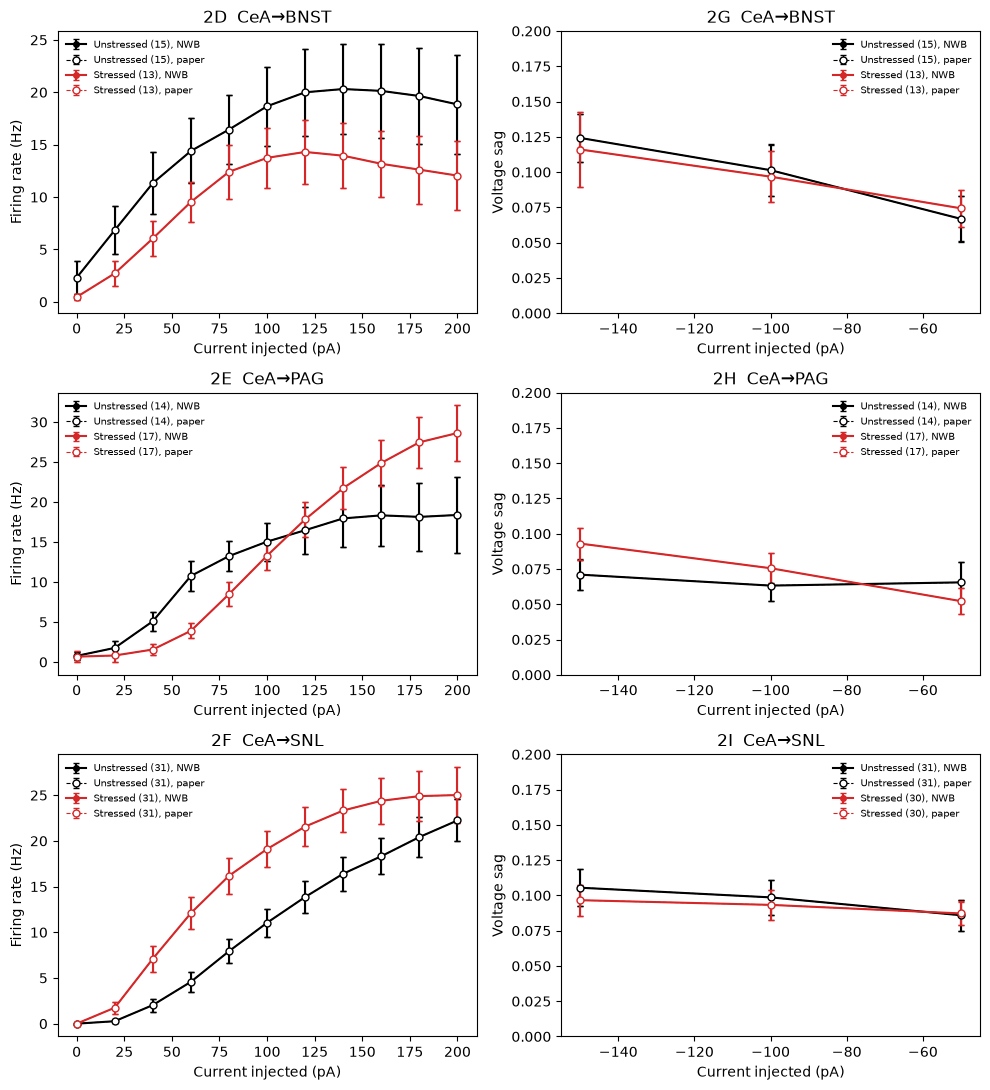

In [5]:
figure, axes = plt.subplots(3, 2, figsize=(10, 11))
for row, (projection_target, fi_panel, sag_panel) in enumerate([("BNST", "2D", "2G"), ("PAG", "2E", "2H"), ("SNL", "2F", "2I")]):
    plot_curve_panel(axes[row, 0], fi_panel, "firing_rate", projection_target)
    axes[row, 0].set_ylabel("Firing rate (Hz)")
    plot_curve_panel(axes[row, 1], sag_panel, "sag", projection_target)
    axes[row, 1].set_ylabel("Voltage sag")
    axes[row, 1].set_ylim(0, 0.2)
figure.tight_layout()
plt.show()

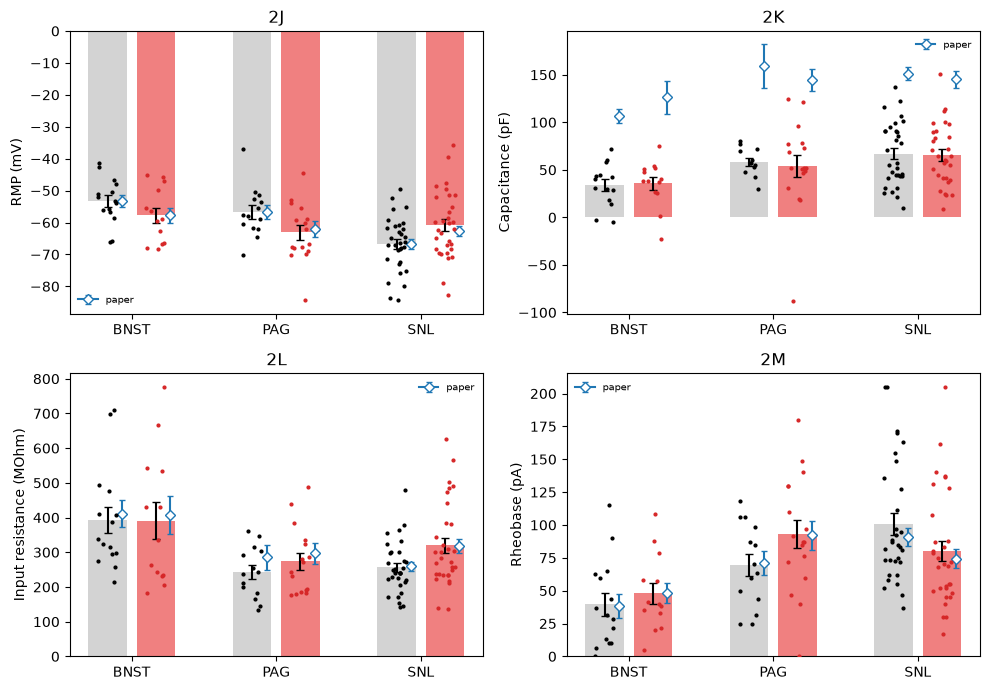

In [6]:
figure, axes = plt.subplots(2, 2, figsize=(10, 7))
plot_bar_panel(axes[0, 0], "2J", "rmp", "RMP (mV)")
plot_bar_panel(axes[0, 1], "2K", "capacitance_pF", "Capacitance (pF)")
plot_bar_panel(axes[1, 0], "2L", "input_resistance_MOhm", "Input resistance (MOhm)")
plot_bar_panel(axes[1, 1], "2M", "rheobase", "Rheobase (pA)")
figure.tight_layout()
plt.show()

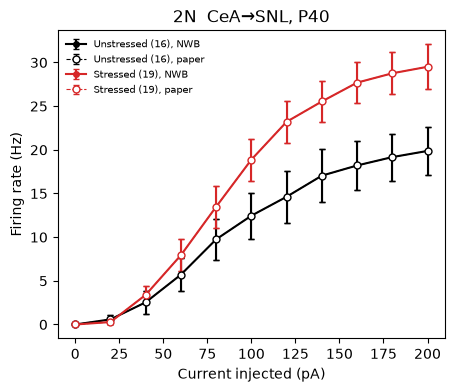

In [7]:
figure, axis = plt.subplots(figsize=(5, 4))
plot_curve_panel(axis, "2N", "firing_rate", "SNL", age_group="P40")
axis.set_ylabel("Firing rate (Hz)")
axis.set_title("2N  CeA→SNL, P40")
plt.show()

## Supplementary Figure 4

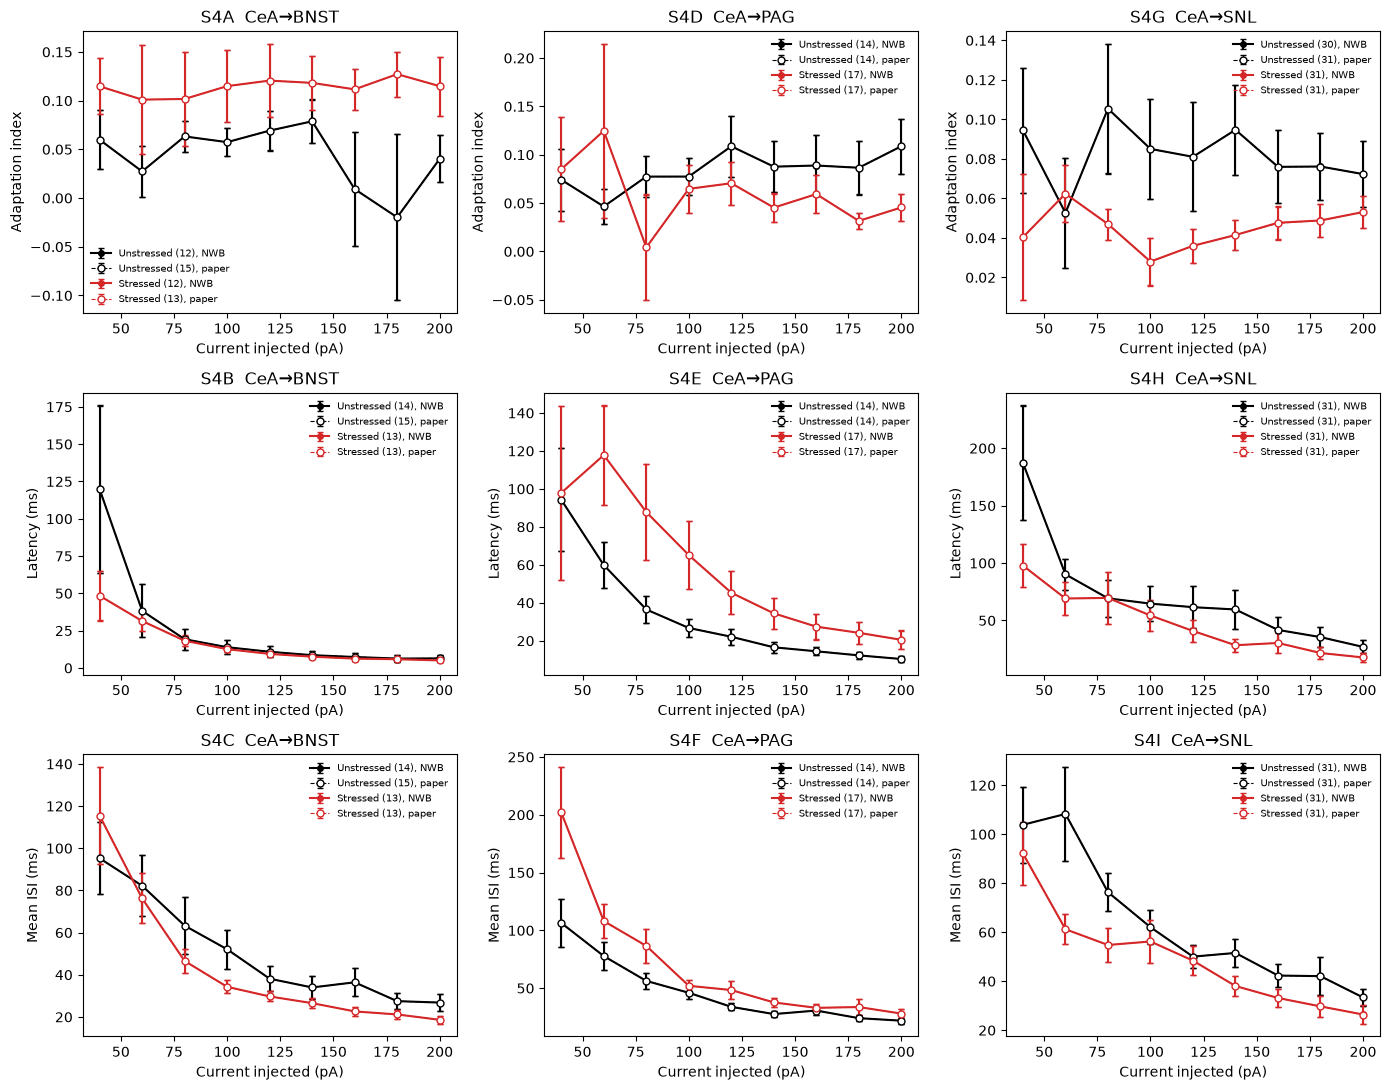

In [8]:
figure, axes = plt.subplots(3, 3, figsize=(14, 11))
currents = range(40, 201, 20)
for column, (projection_target, letters) in enumerate([("BNST", "ABC"), ("PAG", "DEF"), ("SNL", "GHI")]):
    for row, (letter, feature, ylabel) in enumerate(
        zip(letters, ["adaptation_index", "latency", "mean_isi"], ["Adaptation index", "Latency (ms)", "Mean ISI (ms)"])
    ):
        plot_curve_panel(axes[row, column], "S4" + letter, feature, projection_target, currents=currents)
        axes[row, column].set_ylabel(ylabel)
figure.tight_layout()
plt.show()

## Agreement with the reported values

For each panel and group: the number of cells here and in the preprint, and the largest difference between the mean computed here and the reported mean, in units of the reported SEM.

In [9]:
FEATURES = {"firing_rate": "firing_rate", "firing_rate_p40": "firing_rate", "sag": "sag", "adaptation_index": "adaptation_index",
            "latency": "latency", "mean_isi": "mean_isi", "rmp": "rmp", "capacitance": "capacitance_pF",
            "input_resistance": "input_resistance_MOhm", "rheobase": "rheobase"}
rows = []
for (panel, feature, projection_target, stress_group), paper in paper_values.groupby(
    ["panel", "feature", "projection_target", "stress_group"], sort=False
):
    column = FEATURES[feature]
    age_group = "P40" if feature == "firing_rate_p40" else "P70"
    if paper["current_pA"].isna().all():
        group = per_cell[(per_cell["projection_target"] == projection_target) & (per_cell["stress_group"] == stress_group)
                         & (per_cell["age_group"] == age_group)]
        data = group.loc[~group[column + "_outlier"], column].dropna()
        ours = pd.Series([data.mean()], index=[np.nan])
        n_cells = len(data)
    else:
        data = per_current[(per_current["projection_target"] == projection_target) & (per_current["stress_group"] == stress_group)
                           & (per_current["age_group"] == age_group)].reset_index()
        if panel.startswith("S4"):
            paper = paper[paper["current_pA"] >= 40]
        ours = data.groupby("current_pA")[column].mean().reindex(paper["current_pA"])
        n_cells = data.dropna(subset=[column])["cell"].nunique()
    difference = (ours.to_numpy() - paper["mean"].to_numpy()) / paper["sem"].replace(0, np.nan).to_numpy()
    rows.append(dict(panel=panel, projection_target=projection_target, stress_group=stress_group, cells_here=n_cells,
                     cells_paper=int(paper["n_cells"].iloc[0]), largest_difference_in_sem=np.nanmax(np.abs(difference))))
agreement = pd.DataFrame(rows)
agreement.round(2)

,panel,projection_target,stress_group,cells_here,cells_paper,largest_difference_in_sem
0,2D,BNST,naive,15,15,0.00
1,2D,BNST,stress,13,13,0.00
2,2E,PAG,naive,14,14,0.00
3,2E,PAG,stress,17,17,0.00
4,2F,SNL,naive,31,31,0.00
5,2F,SNL,stress,31,31,0.00
6,2G,BNST,naive,15,15,0.00
7,2G,BNST,stress,13,13,0.00
8,2H,PAG,naive,14,14,0.00
9,2H,PAG,stress,17,17,0.00


## Where the reproduction differs from the preprint

Every curve panel (2D to 2I, 2N, and S4A to S4I) matches the preprint's statistics table. The bar panels differ in two places:

- Rheobase (2M). For seven cells the lab averaged only some of the rheobase runs, and for eight cells it used the F-I steps although the 5 pA protocol was recorded; here every 5 pA run is used wherever the protocol exists. `m112 s4c2` and `m113 s2c2` have no 5 pA protocol and are not in the lab's rheobase values; here they use the F-I steps.
- Capacitance (2K). The charge of the test pulse transient gives about half the reported values, and the lab's method is not described in the preprint.